# UK Turnout Analysis Project

## NB04: Regression Analysis

This notebook models constituency-level turnout at the 2024 general election using the demographic and socioeconomic predictors constructed in NB02.

Analysis begins with a naive multivariate OLS model to provide an easily-interpretable baseline. Model diagnostics are then used to assess observed multicollinearity, suspected heteroskedasticity, functional form and influential observations before alternative specifications are considered.

These results describe constituency-level associations and should not be interpreted as individual-level or causal effects.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm
from statsmodels.stats.diagnostic import linear_reset


In [2]:
data = pd.read_csv("../data/processed/analysis_data.csv")

assert len(data) == 575
assert data["constituency_code"].is_unique
assert data.notna().all().all()

data["log_population_density"] = np.log(
    data["population_density"]
)

In [3]:
predictors = [
    "level4_plus_pct",
    "age_18_34_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

### 1. Baseline OLS model

The baseline specification includes all seven predictors identified before modelling. Although exploratory analysis showed substantial correlation among several predictors, they are initially retained so that multicollinearity can be assessed before considering removing variables on the basis of pairwise correlation.

In [4]:
formula = (
    "turnout_pct ~ "
    + " + ".join(predictors)
)

baseline_model = smf.ols(
    formula,
    data=data
).fit()

baseline_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     342.0
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          7.45e-199
Time:                        12:03:15   Log-Likelihood:                -1459.9
No. Observations:                 575   AIC:                             2936.
Df Residuals:                     567   BIC:                             2971.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 35.9554      4.593      7.829      0.000      26.935      44.976
level4_plus_pct            0.4886      0.019     26.303      0.000       0.452       0.525
age_18_34_pct              0.0351      0.044      0.794      0.427      -0.052       0.122
age_65_plus_pct            0.2257      0.053      4.224      0.000       0.121       0.331
owner_occupied_pct         0.1682      0.035      4.866      0.000       0.100       0.236
social_rented_pct         -0.1362      0.038     -3.630      0.000      -0.210      -0.062
unemployment_rate         -0.7581      0.137     -5.522      0.000      -1.028      -0.488
log_population_density    -0.3854      0.164     -2.344      0.019      -0.708      -0.062
==============================================================================
Omnibus:                       43.850   Durbin-Watson:                   1.696
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              110.212
Skew:                          -0.387   Prob(JB):                     1.17e-24
Kurtosis:                       5.000   Cond. No.                     2.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Baseline model results

The naive model explains ~81% of the variation in constituency turnout. Educational attainment, population share aged 65 and over, and owner occupation are positively associated with turnout, while social renting, unemployment and population density show negative association with turnout.

The biggest change compared to the bivariate analysis involved population share aged 18–34. While younger constituencies display substantially lower turnout in the raw data, this association becomes small and statistically insignificant (p=0.427) once the other predictors are included. This is consistent with strong pairwise correlations observed between age structure, housing tenure, unemployment and population density im NB03.

These coefficients are conditional associations rather than causal effects, and the strong correlations among predictors require further multicollinearity diagnostics before the coefficients are interpreted more substantively.

#### Multicollinearity Diagnostics

In [5]:
X = sm.add_constant(data[predictors])

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif = vif[vif["variable"] != "const"]

vif.sort_values("VIF", ascending=False)

,variable,VIF
4,owner_occupied_pct,9.850287
3,age_65_plus_pct,7.017139
2,age_18_34_pct,6.562311
6,unemployment_rate,4.327910
5,social_rented_pct,3.972289
7,log_population_density,3.371889
1,level4_plus_pct,1.691469


Variance inflation factors confirm substantial overlap between a group of predictors.

Owner occupation has the highest VIF (~9.9), and both age structure measures have VIFs >6. These results are consistent with the earlier correlation analysis: older constituencies tend to have higher owner-occupation rates, while younger constituencies tend to be more densely populated, have higher unemployment, and contain more rented housing.

Educational attainment displays relatively little collinearity with the other predictors.

These VIFs indicate that some coefficients in the full specification may be unstable.  Reduced specifications will thus be compared to assess whether removing severely collinear predictors can stabilise these coefficients without substantially reducing model fit.

In [6]:
reduced_predictors = [
    "level4_plus_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

reduced_formula = (
    "turnout_pct ~ "
    + " + ".join(reduced_predictors)
)

reduced_model = smf.ols(
    reduced_formula,
    data=data
).fit()

reduced_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     399.2
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          4.89e-200
Time:                        12:03:15   Log-Likelihood:                -1460.2
No. Observations:                 575   AIC:                             2934.
Df Residuals:                     568   BIC:                             2965.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 38.2863      3.531     10.842      0.000      31.350      45.222
level4_plus_pct            0.4887      0.019     26.317      0.000       0.452       0.525
age_65_plus_pct            0.2014      0.044      4.601      0.000       0.115       0.287
owner_occupied_pct         0.1577      0.032      4.941      0.000       0.095       0.220
social_rented_pct         -0.1432      0.036     -3.928      0.000      -0.215      -0.072
unemployment_rate         -0.7362      0.134     -5.476      0.000      -1.000      -0.472
log_population_density    -0.4061      0.162     -2.502      0.013      -0.725      -0.087
==============================================================================
Omnibus:                       43.189   Durbin-Watson:                   1.699
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.107
Skew:                          -0.372   Prob(JB):                     7.47e-25
Kurtosis:                       5.021   Cond. No.                     2.15e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [7]:
X_reduced = sm.add_constant(
    data[reduced_predictors]
)

vif_reduced = pd.DataFrame({
    "variable": X_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_reduced.values, i)
        for i in range(X_reduced.shape[1])
    ]
})

vif_reduced = vif_reduced[
    vif_reduced["variable"] != "const"
]

vif_reduced.sort_values("VIF", ascending=False)

,variable,VIF
3,owner_occupied_pct,8.398985
2,age_65_plus_pct,4.711540
5,unemployment_rate,4.153457
4,social_rented_pct,3.752559
6,log_population_density,3.287003
1,level4_plus_pct,1.691400


In [8]:
pd.DataFrame({
    "Full model": [
        baseline_model.rsquared_adj,
        baseline_model.aic,
        baseline_model.bic
    ],
    "Reduced model": [
        reduced_model.rsquared_adj,
        reduced_model.aic,
        reduced_model.bic
    ]
}, index=[
    "Adjusted R²",
    "AIC",
    "BIC"
])

,Full model,Reduced model
Adjusted R²,0.806151,0.806277
AIC,2935.840460,2934.479785
BIC,2970.675420,2964.960376


#### Reduced baseline specification

Removing the share aged 18–34 has virtually no effect on model fit. R^2 is nearly identical (0.808 vs 0.809), while adjusted R^2 marginally increases and both AIC and BIC improve.

Multicollinearity also improves: VIF for the population share >=65 falls below 5, and the VIF for owner occupation declines. The remaining coefficient estimates are broadly stable.

This six-predictor specification is therefore used as the preferred linear baseline. Owner occupation continues to exhibit relatively high collinearity (VIF ~8.4), but it is retained at this stage because it represents a substantively distinct housing characteristic and its estimated coefficient is stable across the two specifications.

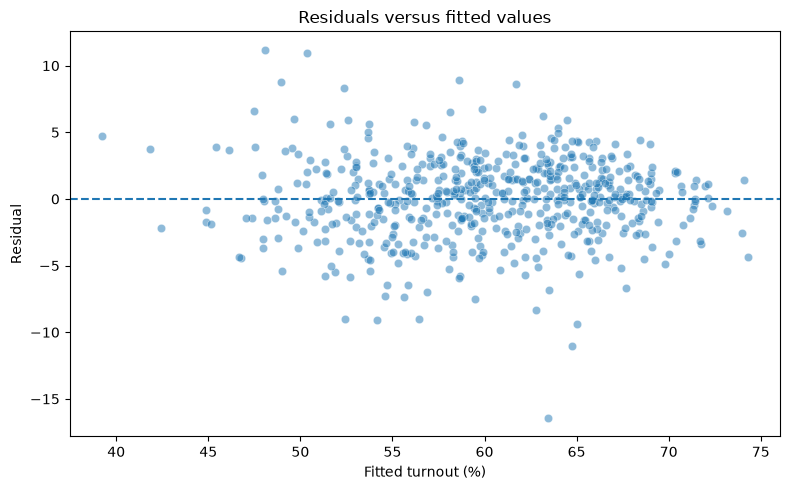

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    x=reduced_model.fittedvalues,
    y=reduced_model.resid,
    alpha=0.5,
    ax=ax
)

ax.axhline(0, linestyle="--")

ax.set_xlabel("Fitted turnout (%)")
ax.set_ylabel("Residual")
ax.set_title("Residuals versus fitted values")

plt.tight_layout()

plt.savefig(
    "../figures/residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
bp_test = het_breuschpagan(
    reduced_model.resid,
    reduced_model.model.exog
)

bp_results = pd.Series(
    bp_test,
    index=[
        "LM statistic",
        "LM p-value",
        "F statistic",
        "F p-value"
    ]
)

bp_results

LM statistic    20.416109
LM p-value       0.002334
F statistic      3.485000
F p-value        0.002158
dtype: float64

In [11]:
reduced_model_hc3 = reduced_model.get_robustcov_results(
    cov_type="HC3"
)

reduced_model_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     380.3
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          3.02e-195
Time:                        12:03:16   Log-Likelihood:                -1460.2
No. Observations:                 575   AIC:                             2934.
Df Residuals:                     568   BIC:                             2965.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 38.2863      3.513     10.897      0.000      31.386      45.187
level4_plus_pct            0.4887      0.019     25.159      0.000       0.451       0.527
age_65_plus_pct            0.2014      0.042      4.840      0.000       0.120       0.283
owner_occupied_pct         0.1577      0.038      4.165      0.000       0.083       0.232
social_rented_pct         -0.1432      0.042     -3.447      0.001      -0.225      -0.062
unemployment_rate         -0.7362      0.154     -4.787      0.000      -1.038      -0.434
log_population_density    -0.4061      0.163     -2.494      0.013      -0.726      -0.086
==============================================================================
Omnibus:                       43.189   Durbin-Watson:                   1.699
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.107
Skew:                          -0.372   Prob(JB):                     7.47e-25
Kurtosis:                       5.021   Cond. No.                     2.15e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 2.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Heteroskedasticity and robust inference

The residual-versus-fitted plot suggests variation in residual dispersion across fitted turnout values. The Breusch–Pagan test rejects the null hypothesis of homoskedastic errors at any conventional significance level (p = 0.002).

The preferred linear specification is therefore reported with HC3 heteroskedasticity-robust standard errors. Robust inference does not materially change the results: all six predictors remain statistically significant and their estimated coefficients are unchanged.

HC3 standard errors are used for subsequent inference from the linear model.

#### Influence diagnostics

Residual diagnostics indicate several unusually large errors. Influence statistics are therefore examined to determine whether any individual constituencies have disproportionate effects on coefficient estimates.

In [12]:
influence = reduced_model.get_influence()

influence_df = pd.DataFrame({
    "constituency_name": data["constituency_name"],
    "studentized_residual": influence.resid_studentized_external,
    "leverage": influence.hat_matrix_diag,
    "cooks_distance": influence.cooks_distance[0]
})

influence_df.nlargest(
    10, "cooks_distance"
)

,constituency_name,studentized_residual,leverage,cooks_distance
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
259,Islington North,2.967087,0.034444,0.044257
264,Kensington and Bayswater,-2.764544,0.037456,0.041995
281,Leicester South,3.704852,0.019843,0.038826
36,Birmingham Ladywood,1.604818,0.086782,0.034866
26,Bethnal Green and Stepney,2.892719,0.027985,0.033976
73,Brighton Pavilion,2.837653,0.023534,0.027384
74,Bristol Central,2.054741,0.040600,0.025380
219,Hampstead and Highgate,-2.220889,0.034696,0.025152
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


In [13]:
influence_df[
    influence_df["studentized_residual"].abs() > 3
].sort_values(
    "studentized_residual",
    key=abs,
    ascending=False
)

,constituency_name,studentized_residual,leverage,cooks_distance
120,Chorley,-5.474537,0.004611,0.018873
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
281,Leicester South,3.704852,0.019843,0.038826
280,Leicester East,3.616713,0.010981,0.020316
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


### 2. Reduced OLS model diagnostics

#### Influential observations

Some constituencies have unusually large residuals or high leverage, although the two do not always coincide.

Chorley has the largest studentized residual but low leverage, meaning that it is poorly predicted but does not have a particularly large effect on the fitted
model. Cities of London and Westminster combines a large residual with
relatively high leverage and consequently has the largest Cook's distance.

A number of observations exceed the conventional `4/n` Cook's-distance
screening threshold. This threshold is treated as a diagnostic flag rather than
as automatic ground for deleting observations. Observations are retained unless there is evidence of error, and the model's sensitivity to the most influential constituencies is assessed separately.

In [14]:
cooks_threshold = 4 / len(data)

flagged_influence = influence_df[
    influence_df["cooks_distance"] > cooks_threshold
].sort_values(
    "cooks_distance",
    ascending=False
)

print("Cook's distance threshold:", cooks_threshold)
print("Flagged constituencies:", len(flagged_influence))

flagged_influence

Cook's distance threshold: 0.006956521739130435
Flagged constituencies: 29


,constituency_name,studentized_residual,leverage,cooks_distance
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
259,Islington North,2.967087,0.034444,0.044257
264,Kensington and Bayswater,-2.764544,0.037456,0.041995
281,Leicester South,3.704852,0.019843,0.038826
36,Birmingham Ladywood,1.604818,0.086782,0.034866
26,Bethnal Green and Stepney,2.892719,0.027985,0.033976
73,Brighton Pavilion,2.837653,0.023534,0.027384
74,Bristol Central,2.054741,0.040600,0.025380
219,Hampstead and Highgate,-2.220889,0.034696,0.025152
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


In [15]:
top_influential = (
    influence_df
    .nlargest(5, "cooks_distance")
    ["constituency_name"]
    .tolist()
)

sensitivity_data = data[
    ~data["constituency_name"].isin(top_influential)
].copy()

sensitivity_model = smf.ols(
    reduced_formula,
    data=sensitivity_data
).fit(cov_type="HC3")

sensitivity_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.819
Method:                 Least Squares   F-statistic:                     423.4
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          5.51e-205
Time:                        12:03:16   Log-Likelihood:                -1426.0
No. Observations:                 570   AIC:                             2866.
Df Residuals:                     563   BIC:                             2896.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 40.2214      3.317     12.125      0.000      33.720      46.723
level4_plus_pct            0.4896      0.019     26.351      0.000       0.453       0.526
age_65_plus_pct            0.2272      0.038      6.011      0.000       0.153       0.301
owner_occupied_pct         0.1253      0.032      3.857      0.000       0.062       0.189
social_rented_pct         -0.1631      0.038     -4.266      0.000      -0.238      -0.088
unemployment_rate         -0.8811      0.145     -6.074      0.000      -1.165      -0.597
log_population_density    -0.3194      0.158     -2.020      0.043      -0.629      -0.009
==============================================================================
Omnibus:                       44.516   Durbin-Watson:                   1.729
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              104.977
Skew:                          -0.419   Prob(JB):                     1.60e-23
Kurtosis:                       4.928   Cond. No.                     2.16e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 2.16e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [16]:
coefficient_comparison = pd.DataFrame({
    "Preferred model": reduced_model_hc3.params,
    "Sensitivity model": sensitivity_model.params
})

coefficient_comparison["difference"] = (
    coefficient_comparison["Sensitivity model"]
    - coefficient_comparison["Preferred model"]
)

coefficient_comparison

,Preferred model,Sensitivity model,difference
Intercept,38.286337,40.221377,1.935040
level4_plus_pct,0.488671,0.489582,0.000911
age_65_plus_pct,0.201357,0.227234,0.025877
owner_occupied_pct,0.157664,0.125271,-0.032393
social_rented_pct,-0.143181,-0.163112,-0.019931
unemployment_rate,-0.736214,-0.881147,-0.144933
log_population_density,-0.406096,-0.319351,0.086745


#### Sensitivity to influential observations

A sensitivity specification excludes the five constituencies with the largest Cook's distances and re-estimates the preferred model using HC3 robust standard errors.

The main results remain stable: coefficient signs are all unchanged and the six predictors remain statistically significant. Educational attainment is
almost completely unaffected, while the estimated associations for owner
occupation, unemployment and population density change only in magnitude.

Population density is the least robust of the retained predictors, with a smaller estimated coefficient and weaker significance after the most influential observations are excluded.

The full 575-constituency specification is retained as the preferred model. Influential constituencies are valid observations and are excluded here only as a sensitivity test rather than as part of the main analysis.

#### Functional-form diagnostics

The exploratory analysis suggested possible nonlinear bivariate relationships
between turnout and several predictors. However, these relationships may partly
reflect the substantial correlation among constituency characteristics.


In [17]:
reset_test = linear_reset(
    reduced_model,
    power=2,
    use_f=True
)

print(reset_test)

<F test: F=0.08288191844330726, p=0.7735344564525537, df_denom=567, df_num=1>


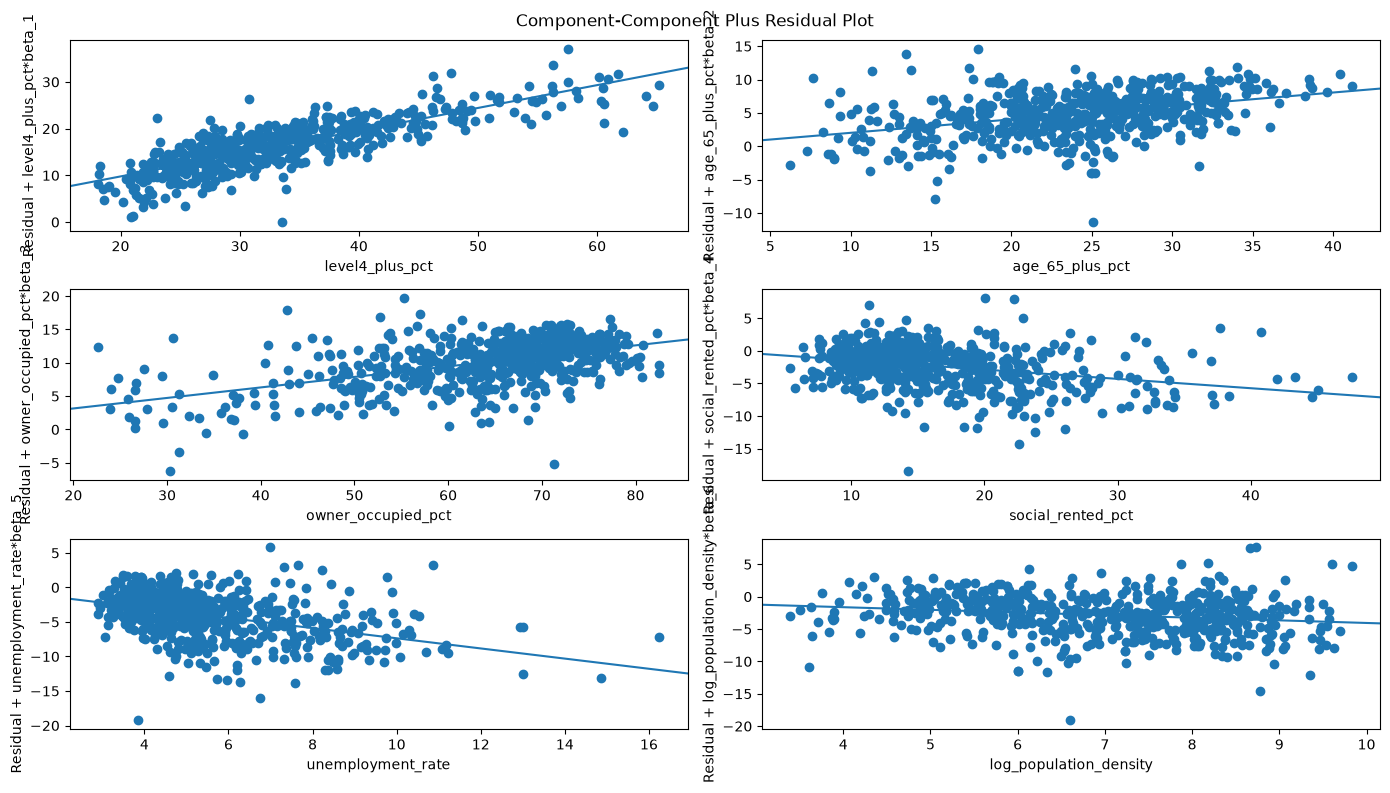

In [18]:
fig = plt.figure(figsize=(14, 10))

sm.graphics.plot_ccpr_grid(
    reduced_model,
    fig=fig
)

plt.tight_layout()
plt.show()

In [19]:
reset_test_hc3 = linear_reset(
    reduced_model,
    power=2,
    use_f=True,
    cov_type="HC3"
)

print(reset_test_hc3)

<F test: F=0.0697968566936593, p=0.7917287835459411, df_denom=567, df_num=1>


A Ramsey RESET test shows no evidence of functional-form misspecification in
the preferred multivariable model (p=0.774). Component-plus-residual plots also
show no strong shape once the other predictors are held constant.

The linear specification is therefore retained rather than adding polynomial
terms that are not supported by the multivariable diagnostics.

### 3. Preferred regression results

The preferred OLS specification contains six predictors and uses HC3 heteroskedasticity-robust standard errors. Results are presented below as percentage-point associations with constituency turnout.

In [20]:
confidence_intervals = reduced_model_hc3.conf_int()

results_table = pd.DataFrame({
    "variable": reduced_model.model.exog_names,
    "coefficient": reduced_model_hc3.params,
    "std_error": reduced_model_hc3.bse,
    "p_value": reduced_model_hc3.pvalues,
    "ci_lower": confidence_intervals[:, 0],
    "ci_upper": confidence_intervals[:, 1]
})

results_table

,variable,coefficient,std_error,p_value,ci_lower,ci_upper
0,Intercept,38.286337,3.513393,3.063120e-25,31.385509,45.187165
1,level4_plus_pct,0.488671,0.019423,2.033207e-94,0.450521,0.526821
2,age_65_plus_pct,0.201357,0.041605,1.677471e-06,0.119639,0.283075
3,owner_occupied_pct,0.157664,0.037850,3.590396e-05,0.083321,0.232007
4,social_rented_pct,-0.143181,0.041543,6.097597e-04,-0.224778,-0.061584
5,unemployment_rate,-0.736214,0.153805,2.165436e-06,-1.038311,-0.434117
6,log_population_density,-0.406096,0.162804,1.290067e-02,-0.725868,-0.086325


In [21]:
coefficient_labels = {
    "Intercept": "Intercept",
    "level4_plus_pct": "Level 4+ qualifications",
    "age_65_plus_pct": "Aged 65+",
    "owner_occupied_pct": "Owner-occupied",
    "social_rented_pct": "Social rented",
    "unemployment_rate": "Unemployment rate",
    "log_population_density": "Log population density"
}

results_table["label"] = (
    results_table["variable"]
    .map(coefficient_labels)
)

results_table[
    [
        "label",
        "coefficient",
        "std_error",
        "p_value",
        "ci_lower",
        "ci_upper"
    ]
].round(3)


,label,coefficient,std_error,p_value,ci_lower,ci_upper
0,Intercept,38.286,3.513,0.000,31.386,45.187
1,Level 4+ qualifications,0.489,0.019,0.000,0.451,0.527
2,Aged 65+,0.201,0.042,0.000,0.120,0.283
3,Owner-occupied,0.158,0.038,0.000,0.083,0.232
4,Social rented,-0.143,0.042,0.001,-0.225,-0.062
5,Unemployment rate,-0.736,0.154,0.000,-1.038,-0.434
6,Log population density,-0.406,0.163,0.013,-0.726,-0.086


In [22]:
results_table.to_csv(
    "../tables/preferred_regression_results.csv",
    index=False
)

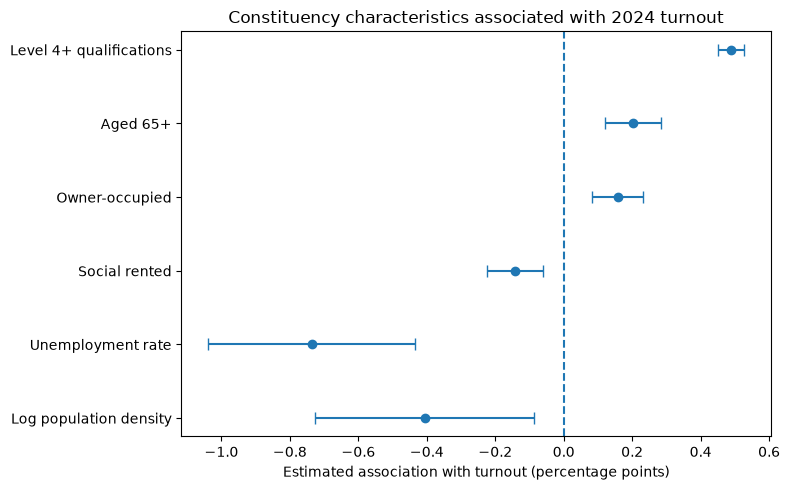

In [23]:
plot_data = (
    results_table[
        results_table["variable"] != "Intercept"
    ]
    .copy()
    .iloc[::-1]
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    plot_data["coefficient"],
    plot_data["label"],
    xerr=[
        plot_data["coefficient"] - plot_data["ci_lower"],
        plot_data["ci_upper"] - plot_data["coefficient"]
    ],
    fmt="o",
    capsize=4
)

ax.axvline(0, linestyle="--")

ax.set_xlabel("Estimated association with turnout (percentage points)")
ax.set_ylabel("")
ax.set_title("Constituency characteristics associated with 2024 turnout")

plt.tight_layout()

plt.savefig(
    "../figures/regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
density_doubling_effect = (
    reduced_model.params["log_population_density"]
    * np.log(2)
)

density_doubling_effect

np.float64(-0.28148461800173186)

### 4. Regression analysis summary

The preferred model explains around 81% of the variation in turnout between
constituencies. Higher educational attainment, an older population and greater
owner occupation are associated with higher turnout, while social renting,
unemployment and population density are associated with lower turnout.

The clearest result is the relationship with education. Holding the other
constituency characteristics constant, a one percentage-point increase in the
share of residents with Level 4 qualifications or above is associated with
around 0.49pp higher turnout. This relationship is also notably
stable across the different specifications tested.

Unemployment shows a similarly clear relationship in the opposite direction.
A 1pp higher unemployment rate is associated with roughly
0.74pp lower turnout. The relationships with age, housing tenure
and density are smaller, but remain present after accounting for the other
characteristics in the model. In the case of population density, a doubling of
density is associated with around 0.28pp lower turnout.

There are, however, some reasons to be cautious about treating these estimates
too literally. Several of the predictors are strongly related to one another:
older constituencies, for example, also tend to have higher rates of owner
occupation and lower population density. The 18–34 age measure added very little
once these overlapping characteristics were taken into account, and removing it
reduced multicollinearity without weakening the model.

The residuals also show evidence of heteroskedasticity, so HC3 robust standard
errors are used for inference. A small number of constituencies are relatively
influential, but excluding the five most influential observations does not change
the direction or statistical significance of any of the main results. Population
density is somewhat less stable than the other estimates, but the overall pattern
remains much the same.

Finally, although some of the raw relationships appeared nonlinear during the
exploratory analysis, this largely disappears once the predictors are considered
together. Ramsey RESET tests provide no evidence that the preferred linear model
is misspecified, so I do not think adding polynomial terms would improve the
analysis enough to justify the additional complexity.

These results should therefore be read as evidence about the characteristics of
high- and low-turnout constituencies, rather than as causal effects. They also
cannot tell us that an individual with a particular characteristic is more or
less likely to vote: the analysis is at constituency level, and making that jump
would risk an ecological fallacy.